# Heart Disease ditection Project 😕

Our main focus is to evaluate patient records and predict wheather a patient has heart disease or not. 

Some key steps to follow:
1. Problem Definition
2. Data
3. Evaluation
4. Features
5. Modeling

## 1. Problem Def:
> We have to predict data from patients health matrics such as(age, sex, heartRate.. etc.) and predict wheather a patient has heart disease or not

## 2. Data:
> The Data is coming from UCI Global Heart Disease Data set: https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data?resource=download

## Evaluation:
> If we can achieve atleast 95% accuracy predicting wheater a patient has heart-disease or not. That's where we persue this project.

## 3. Featurees:

**Features Dictionary**
- id (Unique id for each patient)
- age (Age of the patient in years)
- origin (place of study)
- sex (1 = male; 0 = female)
- cp: chest pain type
        -- Value 1: typical angina
        -- Value 2: atypical angina
        -- Value 3: non-anginal pain
        -- Value 4: asymptomatic
- trestbps resting blood pressure (resting blood pressure (in mm Hg on admission to the hospital))
- chol (serum cholesterol in mg/dl)
- fbs (fasting blood sugar > 120 mg/dl)  (1 = true; 0 = false)
- restecg: resting electrocardiographic results
        -- Value 0: normal
        -- Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
        -- Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria
- thalach: maximum heart rate achieved
- exang: exercise induced angina (1 = yes; 0 = no)
- oldpeak: ST depression induced by exercise relative to rest
- slope: the slope of the peak exercise ST segment
        -- Value 1: upsloping
        -- Value 2: flat
        -- Value 3: downsloping
- ca: number of major vessels (0-3) colored by fluoroscopy
- thal: 3 = normal; 6 = fixed defect; 7 = reversable defect
- num: diagnosis of heart disease (angiographic disease status)
        -- Value 0: < 50% diameter narrowing
        -- Value 1: > 50% diameter narrowing

In [1]:
# Now let's get our tools ready
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier 

from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.model_selection import cross_val_score, train_test_split

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score

## Explore Data (EDA)

In [2]:
df = pd.read_csv("heart-disease.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [4]:
df["target"].value_counts()

target
1    165
0    138
Name: count, dtype: int64

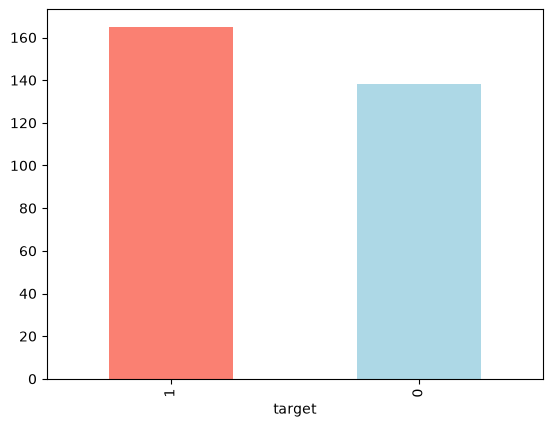

In [5]:
df["target"].value_counts().plot(kind="bar", color=["salmon", "lightblue"]);

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [7]:
df.shape

(303, 14)

In [8]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

### So, by exploring we found out that we don't have any null values. Now we can start with our next steps 😀

In [9]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


### Now we will create a comparison of sex how many male and female has heart-disease or not

In [10]:
df["sex"].value_counts()

sex
1    207
0     96
Name: count, dtype: int64

In [11]:
df["target"].value_counts()

target
1    165
0    138
Name: count, dtype: int64

In [12]:
pd.crosstab(df.target, df.sex) # So 1 is male and 0 is female

sex,0,1
target,,
0,24,114
1,72,93


> According to this dataset we have 96 women. Roughly 70-75% women has heart disease and rest of 25-30% don't have heart disease
> Similarly, around 45% men has heart disease and 50-55% men doesn't has heart disease

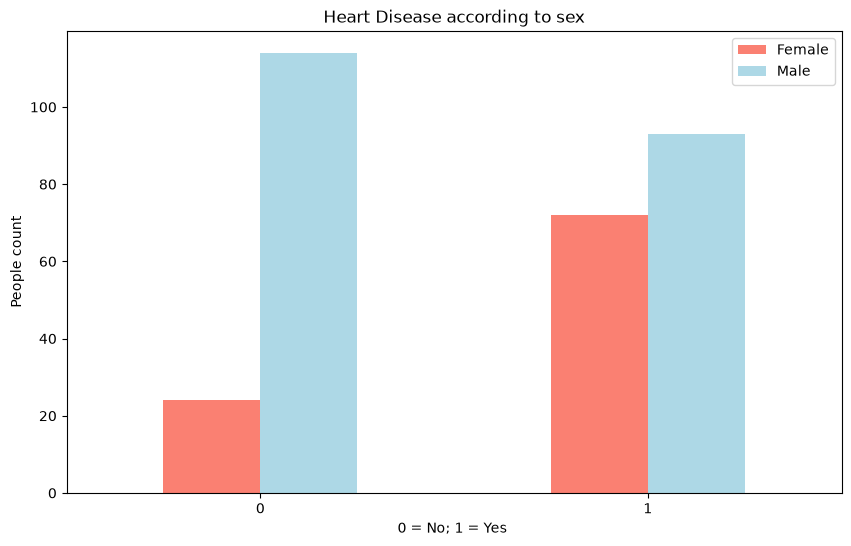

In [13]:
pd.crosstab(df.target, df.sex).plot(kind="bar", figsize=(10,6), color=["salmon", "lightblue"]);
plt.title("Heart Disease according to sex")
plt.xlabel("0 = No; 1 = Yes ")
plt.ylabel("People count")
plt.legend(["Female", "Male"])
plt.xticks(rotation=0)
plt.show()

In [14]:
df["thalach"].value_counts()

thalach
162    11
163     9
160     9
173     8
152     8
       ..
117     1
71      1
118     1
134     1
90      1
Name: count, Length: 91, dtype: int64

In [15]:
df["thalach"].max()

np.int64(202)

### Let's compare this with sex 
> So sex Vs. thalache

In [16]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


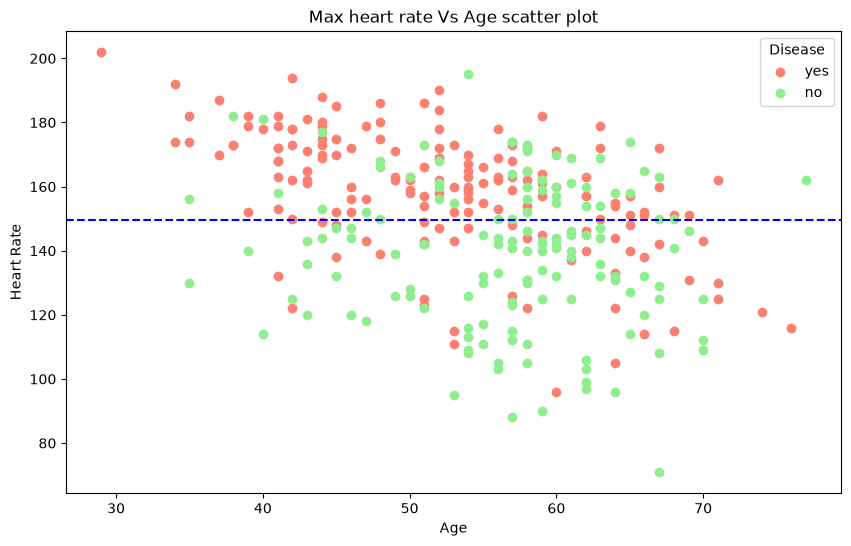

In [17]:
# We will create a scatter plot 
fig = plt.figure(figsize=(10,6))

# First we are trying to look at age Vs thalache when they have heart disease
plt.scatter(df.age[df.target==1],
           df.thalach[df.target==1],
           c=["salmon"])

# Secondly we will look at age Vs thalache when they doesn't have heart disease
plt.scatter(df.age[df.target==0],
           df.thalach[df.target==0],
           c=["lightgreen"])
plt.axhline(np.mean(df.thalach), linestyle="--", color="b")

plt.title("Max heart rate Vs Age scatter plot")
plt.xlabel("Age")
plt.ylabel("Heart Rate")
plt.legend(["yes", "no"], title="Disease")
plt.savefig("plots/hr_vs_age.png")
plt.show();

- cp: chest pain type
     - Value 1: typical angina
     - Value 2: atypical angina
     - Value 3: non-anginal pain
     - Value 4: asymptomatic

In [18]:
# Now let's look at the chest pain vs target. 
pd.crosstab(df.cp, df.target)

target,0,1
cp,,
0,104,39
1,9,41
2,18,69
3,7,16


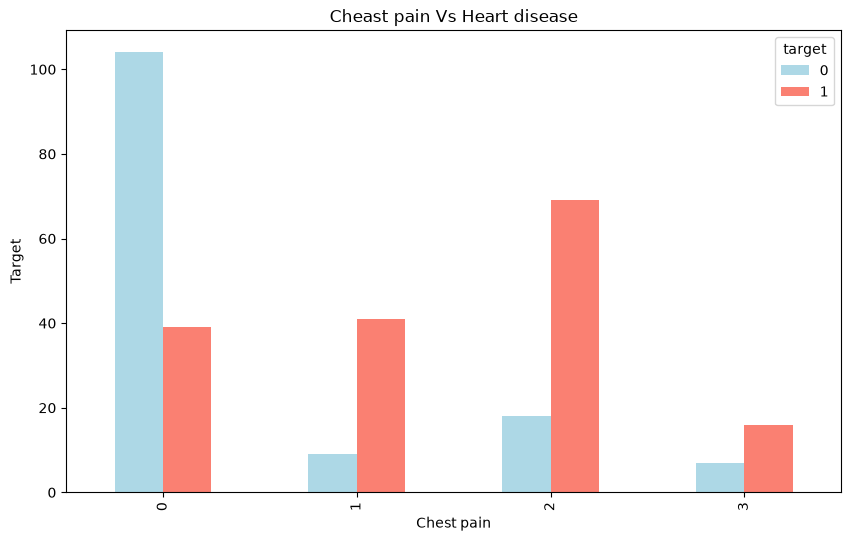

In [19]:
pd.crosstab(df.cp, df.target).plot.bar(color=["lightblue","salmon"], figsize=(10,6))
plt.title("Cheast pain Vs Heart disease")
plt.xlabel("Chest pain")
plt.ylabel("Target")
plt.savefig("plots/cp_vs_disease.png");

> **Now the patterns are not making any sence. I think I have to talk with a Doctor. Why the hell cp = 0 has people with less heart disease  while in 2 there are more 🤯.**

In [21]:
import seaborn as sns

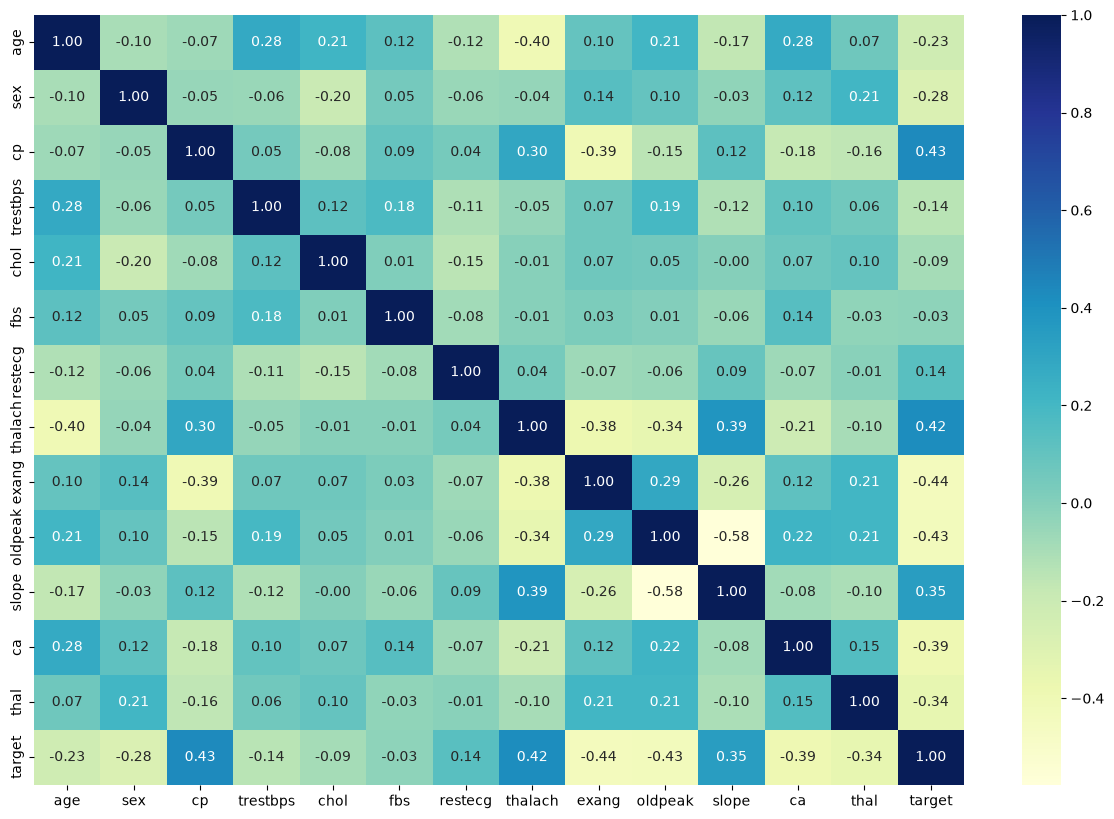

In [23]:
# Let's create a correlation matrix
corr_matrix = df.corr()
fig, ax = plt.subplots(figsize=(15,10))
ax = sns.heatmap(corr_matrix, 
                 annot=True,
                fmt=".2f",
                cmap="YlGnBu")
plt.savefig("plots/correlation.png")

# Modeling:

In [24]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [25]:
# Now we have to Separate our data into X(Features) and Y(Labels) 
X = df.drop("target", axis=1)
Y = df["target"] 

In [26]:
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


In [27]:
Y.head()

0    1
1    1
2    1
3    1
4    1
Name: target, dtype: int64

> This is binary classification, where we have to classify either someone has heart disease or not

In [28]:
# Now we have to split our data into train and test split
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [34]:
len(X), len(Y)

(303, 303)

In [32]:
len(x_train), len(y_train)

(242, 242)

In [33]:
len(x_test), len(y_test)

(61, 61)

## Now we will choose the best Model/Estimator for our machine learing model

*I will experiment with:*

    1. KNeighboursClassifier
    2. RandomForestClassifier
    3. LogisticRegression

In [36]:
from sklearn.neighbors import KNeighborsClassifier

k_clf = KNeighborsClassifier(n_neighbors=5)

k_clf.fit(x_train, y_train)
k_clf.score(x_test, y_test)

0.6885245901639344

In [41]:
"""
Let's try to evaluate the models in one go...
As we have already imported all the models we can take a functional approach
First let's create a dictionary
"""

models = {
    "Logistics Regrassion": LogisticRegression(max_iter=100),
    "RandomForest Classifier": RandomForestClassifier(),
    "KNeighbours Classifier": KNeighborsClassifier()
}

def fit_and_score(models, x_train, x_test, y_train, y_test):
    np.random.seed(42)
    model_score = {}
    # Now we have to fit our model with the data and score
    for name, model in models.items():
        model.fit(x_train, y_train)
        model_score[name] = model.score(x_test,y_test)
    return model_score

In [44]:
base_model_score = fit_and_score(models, x_train, x_test, y_train, y_test)
base_model_score

C:\Users\ASUS\project_1\heart-disease-project\env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'Logistics Regrassion': 0.8852459016393442,
 'RandomForest Classifier': 0.8360655737704918,
 'KNeighbours Classifier': 0.6885245901639344}

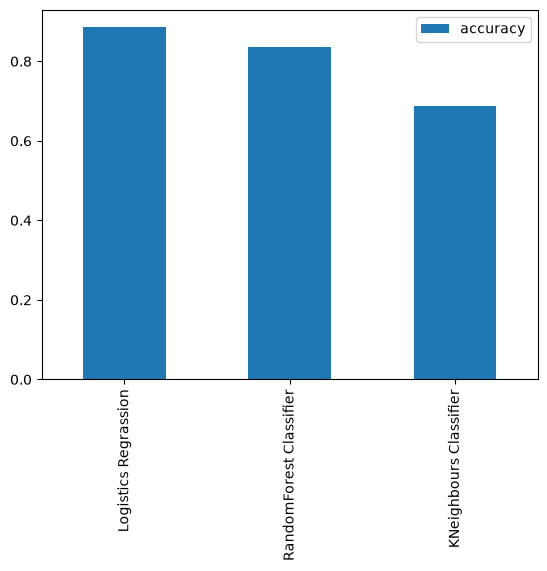

In [50]:
# So our Baseline model performs well in this scenario
pd.DataFrame(base_model_score, index=["accuracy"]).T.plot.bar();

### Now stay Tuned.. OOOOOPPPPSSSSS Spoiler 😶